In [17]:
from pathlib import Path
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Find project root by locating the data folder
current = Path.cwd().resolve()

ROOT = next(
    (p for p in [current, *current.parents]
     if (p / "data").is_dir() and (p / "src").is_dir()),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Could not locate project root containing data/ and src/"
    )

os.chdir(ROOT)

# Project directories
DATA_DIR = ROOT / "data"
SRC_DIR = ROOT / "src"
RESULTS_DIR = ROOT / "results"
SUBMISSIONS_DIR = ROOT / "submissions"

print("Project root:", ROOT)
print("Working directory:", Path.cwd())
print("Data directory:", DATA_DIR)

Project root: C:\Users\Avnish\Documents\GitHub\fleet_maintenance_p2_team38
Working directory: C:\Users\Avnish\Documents\GitHub\fleet_maintenance_p2_team38
Data directory: C:\Users\Avnish\Documents\GitHub\fleet_maintenance_p2_team38\data


In [18]:
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (56000, 174)
Test: (20000, 171)


### Exploratory Data Analysis (EDA):

#### 1. Basic Data Inspection and Missing-Values Analysis:

In [19]:
print("Training information:")
train_df.info()

print("\nTest information:")
test_df.info()

print("\nMissing values in training data:")
display(train_df.isnull().sum().sort_values(ascending=False).head(20))

print("\nMissing values in test data:")
display(test_df.isnull().sum().sort_values(ascending=False).head(20))

print("\nFailure distribution:")
display(train_df["failure"].value_counts(normalize=True) * 100)

print("\nRepair cost statistics:")
display(train_df["repair_cost"].describe())

Training information:
<class 'pandas.DataFrame'>
RangeIndex: 56000 entries, 0 to 55999
Columns: 174 entries, id to s169
dtypes: float64(171), int64(2), str(1)
memory usage: 74.3 MB

Test information:
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Columns: 171 entries, id to s169
dtypes: float64(170), str(1)
memory usage: 26.1 MB

Missing values in training data:


repair_cost    55603
s166           46281
s108           45771
s121           44864
s100           43587
s021           43335
s147           43335
s072           41390
s074           37224
s078           25623
s010           21603
s036           13757
s002           13757
s169           13757
s125           13757
s150           13757
s093           12829
s076           12829
s090           12829
s095           12829
dtype: int64


Missing values in test data:


s047    20000
s166    16112
s108    15932
s121    15597
s021    15357
s147    15357
s100    15122
s072    14332
s074    12871
s078     8880
s010     7525
s036     5085
s169     5085
s125     5085
s002     5085
s150     5085
s070     4697
s076     4697
s095     4697
s093     4697
dtype: int64


Failure distribution:


failure
0    99.291071
1     0.708929
Name: proportion, dtype: float64


Repair cost statistics:


count     397.000000
mean      492.382872
std       993.732983
min         5.000000
25%        71.000000
50%       176.000000
75%       488.000000
max      8000.000000
Name: repair_cost, dtype: float64

#### 2. Failure and Repair Costs Analysis:

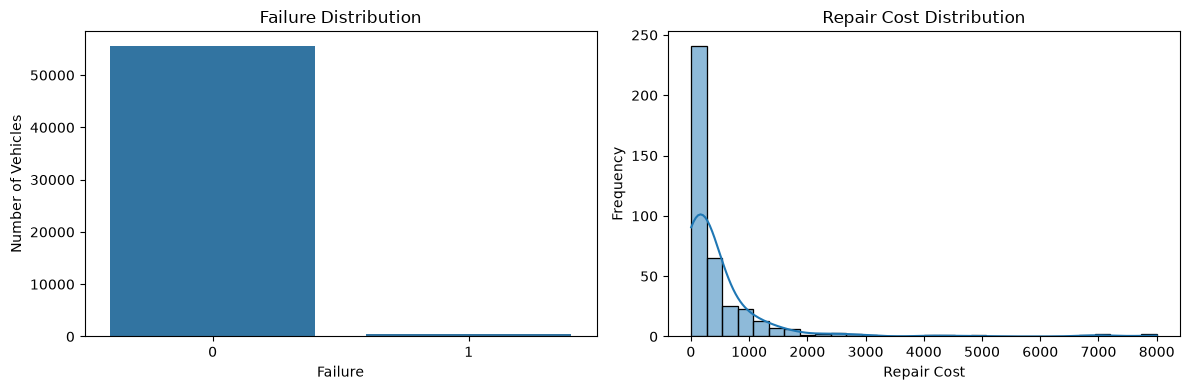

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=train_df, x="failure", ax=axes[0])
axes[0].set_title("Failure Distribution")
axes[0].set_xlabel("Failure")
axes[0].set_ylabel("Number of Vehicles")

sns.histplot(train_df.loc[train_df["failure"] == 1, "repair_cost"], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Repair Cost Distribution")
axes[1].set_xlabel("Repair Cost")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

#### 3. Sensor Missing-Values Analysis:

In [21]:
sensor_cols = [col for col in train_df.columns if col.startswith("s")]

print("Number of sensor columns:", len(sensor_cols))

Number of sensor columns: 170


Total missing sensor values:
Train: 787984
Test: 310475


<Figure size 1200x500 with 0 Axes>

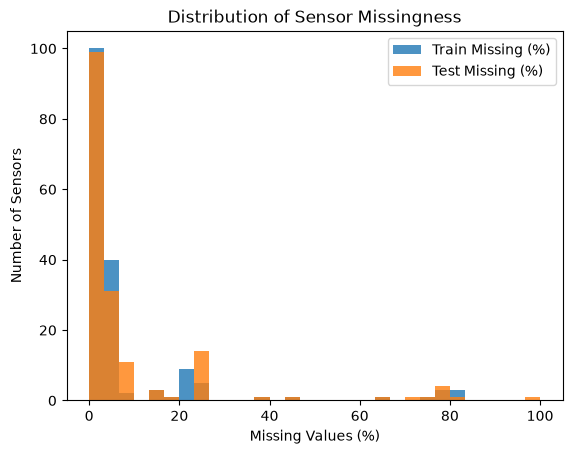

In [22]:
missing_data = pd.DataFrame({
    "Train Missing (%)": train_df[sensor_cols].isnull().mean() * 100,
    "Test Missing (%)": test_df[sensor_cols].isnull().mean() * 100
})

print("Total missing sensor values:")
print("Train:", train_df[sensor_cols].isnull().sum().sum())
print("Test:", test_df[sensor_cols].isnull().sum().sum())

plt.figure(figsize=(12, 5))

missing_data.plot(kind="hist", bins=30, alpha=0.8)
plt.title("Distribution of Sensor Missingness")
plt.xlabel("Missing Values (%)")
plt.ylabel("Number of Sensors")
plt.show()

In [23]:
print("Sensors with more than 50% missing values:")

high_missing = missing_data[missing_data["Train Missing (%)"] > 50].sort_values("Train Missing (%)", ascending=False)

display(high_missing.round(2))

print("Number of highly missing sensors:", len(high_missing))

Sensors with more than 50% missing values:


,Train Missing (%),Test Missing (%)
s166,82.64,80.56
s108,81.73,79.66
s121,80.11,77.98
s100,77.83,75.61
s021,77.38,76.78
s147,77.38,76.78
s072,73.91,71.66
s074,66.47,64.35


Number of highly missing sensors: 8


#### 4. Sensor Value Distribution:

In [24]:
display(train_df[sensor_cols].describe().T[["mean", "std", "min", "50%", "max"]].round(2))

,mean,std,min,50%,max
s000,50567075.04,2.209220e+08,0.0,3350000.0,6.618810e+09
s001,4.23,9.062000e+01,0.0,0.0,1.411957e+04
s002,639160.57,1.312144e+08,0.0,0.0,2.696864e+10
s003,1.07,1.143000e+01,0.0,0.0,8.694200e+02
s004,1.21,5.807000e+01,0.0,0.0,7.027720e+03
...,...,...,...,...,...
s165,196.85,1.303290e+03,0.0,46.4,1.224202e+05
s166,4064781.45,3.637444e+06,0.0,2149512.0,8.597918e+06
s167,0.02,9.300000e-01,0.0,0.0,8.196000e+01
s168,117981.52,4.505931e+06,0.0,0.0,3.883306e+08


In [25]:
constant_sensors = [col for col in sensor_cols if train_df[col].nunique(dropna=True) <= 1]

print("Constant sensors:", constant_sensors)
print("Number of constant sensors:", len(constant_sensors))

Constant sensors: ['s146']
Number of constant sensors: 1


In [26]:
sensor_comparison = pd.DataFrame({
    "Train Mean": train_df[sensor_cols].mean(),
    "Test Mean": test_df[sensor_cols].mean(),
    "Train Std": train_df[sensor_cols].std(),
    "Test Std": test_df[sensor_cols].std()
})

sensor_comparison["Mean Difference (%)"] = (
    (sensor_comparison["Test Mean"] - sensor_comparison["Train Mean"]).abs()
    / (sensor_comparison["Train Mean"].abs() + 1e-8)
) * 100

display(sensor_comparison.sort_values("Mean Difference (%)", ascending=False).head(20).round(2))

,Train Mean,Test Mean,Train Std,Test Std,Mean Difference (%)
s062,313.96,19762.81,18635.61,41495.66,6194.72
s061,18554.08,772360.62,106187.88,1735568.15,4062.75
s064,1.27,21.46,94.09,1609.66,1585.19
s055,943.06,7939.12,2709.42,15514.39,741.85
s098,568.08,3302.33,44120.10,204230.13,481.32
s060,675986.01,3442895.66,1377493.73,8787810.36,409.31
s051,198.56,993.16,25460.89,80361.19,400.18
s005,2443.81,12029.68,189191.53,1069679.58,392.25
s022,3265.62,13238.19,217798.19,1288813.33,305.38
s110,3430.25,12791.66,137111.36,428664.28,272.91


### 5. EDA Summary

- The failure rate is highly imbalanced (0.71%).
- Repair costs are strongly right-skewed.
- Sensor features contain substantial missing values.
- Eight sensors have more than 50% missing values.
- One sensor (`s146`) is constant.
- Several sensors show substantial train–test differences, suggesting potential distribution shift between depots.